In [325]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Task 1.1: Load the dataset into a Pandas DataFrame and inspect its shape, columns, and data types.

In [326]:
df = pd.read_csv("/content/AB_NYC_2019.csv.zip")

In [327]:
df.shape

(48895, 16)

In [328]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [329]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

Task 1.2: Identify which columns are numerical (discrete/continuous)
and which are categorical (nominal/ordinal).

In [330]:
#catagorical
df.describe(include=['object'])

,name,host_name,neighbourhood_group,neighbourhood,room_type,last_review
count,48879,48874,48895,48895,48895,38843
unique,47905,11452,5,221,3,1764
top,Hillside Hotel,Michael,Manhattan,Williamsburg,Entire home/apt,2019-06-23
freq,18,417,21661,3920,25409,1413


In [331]:
#numerical
df.describe(include=['int'])

,id,host_id,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,152.720687,7.029962,23.274466,7.143982,112.781327
std,1.098311e+07,7.861097e+07,240.154170,20.510550,44.550582,32.952519,131.622289
min,2.539000e+03,2.438000e+03,0.000000,1.000000,0.000000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,69.000000,1.000000,1.000000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,106.000000,3.000000,5.000000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,175.000000,5.000000,24.000000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,10000.000000,1250.000000,629.000000,327.000000,365.000000


Task 1.3: Check for missing values across all columns. Write down
which columns have missing data and calculate their percentages.

In [332]:
#columns having missing values
for col in df.columns:
  print(col,df[col].isnull().sum())

id 0
name 16
host_id 0
host_name 21
neighbourhood_group 0
neighbourhood 0
latitude 0
longitude 0
room_type 0
price 0
minimum_nights 0
number_of_reviews 0
last_review 10052
reviews_per_month 10052
calculated_host_listings_count 0
availability_365 0


In [333]:
#percentage
for col in df.columns:
  print((df[col].isnull().sum() / len(df)) * 100)

0.0
0.03272318232948154
0.0
0.04294917680744453
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
20.55833929849678
20.55833929849678
0.0
0.0


Task 2.1: Look at the last_review column. Since it's a date string with
over 10,000 missing values, decide whether to drop the column entirely
or engineer it.

In [334]:
#replacing the values
df['last_review'] = df['last_review'].fillna(df['last_review'].mode()[0])

In [335]:
print(df.isnull().sum())

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                           0
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64


Task 2.2: Look at the reviews_per_month column. If it contains missing
values, investigate why they are missing (Hint: look at the number of
reviews for those rows) and fill them with a logical replacement value.

In [336]:
print(df['reviews_per_month'])

0        0.21
1        0.38
2         NaN
3        4.64
4        0.10
         ... 
48890     NaN
48891     NaN
48892     NaN
48893     NaN
48894     NaN
Name: reviews_per_month, Length: 48895, dtype: float64


In [337]:
#replacing the values with median
df['reviews_per_month'] = df['reviews_per_month'].fillna(df['reviews_per_month'].median())

In [338]:
print(df.isnull().sum())

id                                 0
name                              16
host_id                            0
host_name                         21
neighbourhood_group                0
neighbourhood                      0
latitude                           0
longitude                          0
room_type                          0
price                              0
minimum_nights                     0
number_of_reviews                  0
last_review                        0
reviews_per_month                  0
calculated_host_listings_count     0
availability_365                   0
dtype: int64


Task 2.3: Drop irrelevant identifier columns that won't help a
mathematical model (e.g., URLs, host names, or unique IDs).

In [339]:
#identifying columns
for col in df.select_dtypes(include='object').columns:
  print(col)

name
host_name
neighbourhood_group
neighbourhood
room_type
last_review


In [340]:
#removing columns
object_cols = df.select_dtypes(include=['object']).columns.tolist()
df_filtered = df.drop(object_cols, axis=1)

In [341]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   host_id                         48895 non-null  int64  
 2   latitude                        48895 non-null  float64
 3   longitude                       48895 non-null  float64
 4   price                           48895 non-null  int64  
 5   minimum_nights                  48895 non-null  int64  
 6   number_of_reviews               48895 non-null  int64  
 7   reviews_per_month               48895 non-null  float64
 8   calculated_host_listings_count  48895 non-null  int64  
 9   availability_365                48895 non-null  int64  
dtypes: float64(3), int64(7)
memory usage: 3.7 MB


Task 3.1: Create boxplots or histograms for price and minimum_nights to
visually detect outliers.

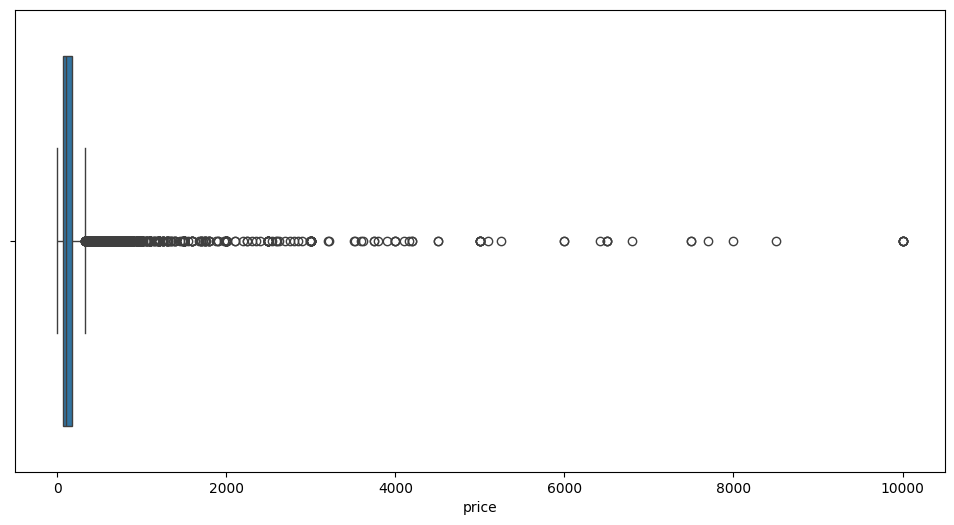

In [342]:
#creating boxplot for price
plt.figure(figsize=(12, 6))
sns.boxplot(x=df_filtered['price'])
plt.show()

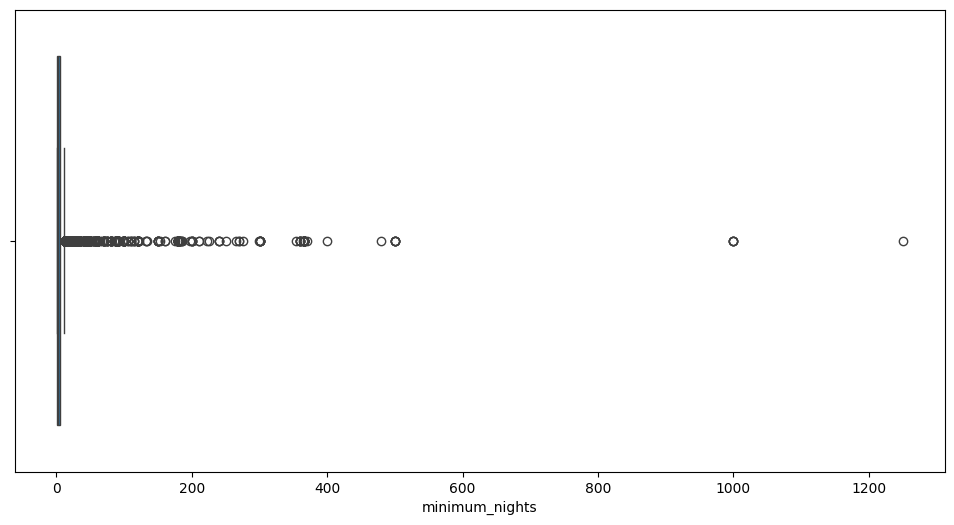

In [343]:
#creating boxplot for minimum_nights
plt.figure(figsize=(12,6))
sns.boxplot(x=df_filtered['minimum_nights'])
plt.show()

Task 3.2: Apply a capping or trimming strategy. Use the 95th percentile
rule to remove extreme luxury penthouses (e.g., $10,000/night listings)
and long-term rental rules (e.g., minimum stays of 365+ nights) so the
model focuses on the typical consumer market.


In [344]:
#adding capping
price_95 = df['price'].quantile(0.95)
min_nights_95 = df['minimum_nights'].quantile(0.95)
df_trimmed = df[
    (df['price'] <= price_95) &
    (df['minimum_nights'] <= min_nights_95)
].copy()

Task 4.1: Address High Cardinality. The dataset has a neighbourhood
column with 200+ unique values and a neighbourhood_group column
with 5 values. Explain why keeping the 200+ unique values will break the
model's simplicity (The Curse of Dimensionality), and drop the
hyper-specific one.

In [345]:
df['neighbourhood'].unique()

array(['Kensington', 'Midtown', 'Harlem', 'Clinton Hill', 'East Harlem',
       'Murray Hill', 'Bedford-Stuyvesant', "Hell's Kitchen",
       'Upper West Side', 'Chinatown', 'South Slope', 'West Village',
       'Williamsburg', 'Fort Greene', 'Chelsea', 'Crown Heights',
       'Park Slope', 'Windsor Terrace', 'Inwood', 'East Village',
       'Greenpoint', 'Bushwick', 'Flatbush', 'Lower East Side',
       'Prospect-Lefferts Gardens', 'Long Island City', 'Kips Bay',
       'SoHo', 'Upper East Side', 'Prospect Heights',
       'Washington Heights', 'Woodside', 'Brooklyn Heights',
       'Carroll Gardens', 'Gowanus', 'Flatlands', 'Cobble Hill',
       'Flushing', 'Boerum Hill', 'Sunnyside', 'DUMBO', 'St. George',
       'Highbridge', 'Financial District', 'Ridgewood',
       'Morningside Heights', 'Jamaica', 'Middle Village', 'NoHo',
       'Ditmars Steinway', 'Flatiron District', 'Roosevelt Island',
       'Greenwich Village', 'Little Italy', 'East Flatbush',
       'Tompkinsville', 'Asto

In [346]:
df['neighbourhood_group'].unique()

array(['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx'],
      dtype=object)

In [347]:
cardinal = df.drop(columns='neighbourhood')

In [348]:
df['neighbourhood'].nunique()

221

Having 200+ values can caues Overfitting to occur or may confuse the model by having it learn many distinct types rather than a patter of some sort.

In [349]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [350]:
#treating null objective type values
emp_col = ['name','host_name']
for col in emp_col:
  df[col]=df[col].fillna(df[col].mode()[0])

In [351]:
df = df.drop(columns=['id', ])

Task 4.2: Convert the remaining categorical columns
(neighbourhood_group and room_type) into numerical format using
One-Hot Encoding. Ensure they drop the first column to avoid the
"Dummy Variable Trap."

In [352]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   name                            48895 non-null  object 
 1   host_id                         48895 non-null  int64  
 2   host_name                       48895 non-null  object 
 3   neighbourhood_group             48895 non-null  object 
 4   neighbourhood                   48895 non-null  object 
 5   latitude                        48895 non-null  float64
 6   longitude                       48895 non-null  float64
 7   room_type                       48895 non-null  object 
 8   price                           48895 non-null  int64  
 9   minimum_nights                  48895 non-null  int64  
 10  number_of_reviews               48895 non-null  int64  
 11  last_review                     48895 non-null  object 
 12  reviews_per_month               

In [353]:
from sklearn.preprocessing import OneHotEncoder

In [354]:
encoder = OneHotEncoder(sparse_output=True, dtype=np.uint8, handle_unknown='ignore')
sparse_matrix = encoder.fit_transform(df[['neighbourhood_group', 'room_type', 'name', 'host_name', 'neighbourhood', 'last_review']])

In [355]:
encoder = OneHotEncoder(sparse_output=True, dtype=np.uint8, handle_unknown='ignore')
sparse_matrix = encoder.fit_transform(df)

In [356]:
'''cols_to_encode = ['neighbourhood_group', 'room_type', 'name', 'host_name', 'neighbourhood', 'last_review']
df_encoded = pd.get_dummies(df, columns=cols_to_encode, drop_first=True, dtype=int)'''#exceeded RAM being used

"cols_to_encode = ['neighbourhood_group', 'room_type', 'name', 'host_name', 'neighbourhood', 'last_review']\ndf_encoded = pd.get_dummies(df, columns=cols_to_encode, drop_first=True, dtype=int)"

Task 5.1: Separate the cleaned data into features ($X$) and the target
variable ($y$).

In [357]:
#separating data
X = df.drop('price', axis=1)
y = df['price']

Task 5.2: Split the data into a Training Set (80%) and a Testing Set
(20%). Ensure they use a specific reproducibility seed (random_state) so
their results can be verified.

In [358]:
from sklearn.model_selection import train_test_split

In [359]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Task 6.1: Import, initialize, and fit a standard Linear Regression model
using the training data.

In [360]:
from sklearn.linear_model import LinearRegression

In [361]:
if 'last_review' in df.columns:
    df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce')
    df['last_review_year'] = df['last_review'].dt.year.fillna(0).astype(int)
    df['last_review_month'] = df['last_review'].dt.month.fillna(0).astype(int)
    df['last_review_day'] = df['last_review'].dt.day.fillna(0).astype(int)
    df = df.drop(columns=['last_review'])

#Convert ALL remaining object/string columns in the DataFrame to integers automatically
for col in df.select_dtypes(include=['object', 'string', 'category']).columns:
    df[col] = df[col].astype('category').cat.codes

#Fill any missing values with 0
df = df.fillna(0)

#RE-CREATE X, y, and X_train (Crucial step!)
X = df.drop(columns=['price'])  # Change 'price' if your target column has a different name
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Fit the model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

Task 6.2: Use the trained model to generate price predictions on the
hidden testing data.

In [362]:
#predicting values
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [363]:
print(y_train_pred[:10], y_test_pred[:10])

[185.12981477 113.9173559   68.67416953 166.52266104  75.88011064
 265.83801933 215.40857823 224.13036618  80.10137206  72.49738048] [196.10190025  87.25966587 113.97704758 238.86995799 173.60292661
 150.75460453  94.36555681 172.15701945 203.49189888 113.1524828 ]


Task 6.3: Calculate three key metrics to grade the model:

○ R-Squared ($R^2$) Score: To find out what percentage of the
price variance the model actually understands.

○ Mean Absolute Error (MAE): To find the average mistake the
model makes in actual US dollars.

○ Mean Squared Error (MSE) / RMSE: To analyze how heavily
the model is being punished for large mistakes.

In [364]:
#Calculate R2 scores by comparing actual y vs predicted y
from sklearn.metrics import r2_score
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
print(train_r2, test_r2)

0.08677874320451928 0.11071434933394386


In [365]:
#Mean absolute error
from sklearn.metrics import mean_absolute_error
print(mean_absolute_error(y_test, y_test_pred), mean_absolute_error(y_train, y_train_pred))

71.858900462038 76.18052884937569


In [366]:
#Mean squared error
from sklearn.metrics import mean_squared_error
print(mean_squared_error(y_test, y_test_pred), mean_squared_error(y_train, y_train_pred))

39340.43018735438 55730.40835203743


Task 7.1: Plot a scatter plot of Actual Prices vs. Predicted Prices. Draw a
$45^\circ$ diagonal line to show what a "perfect" prediction would look
like.

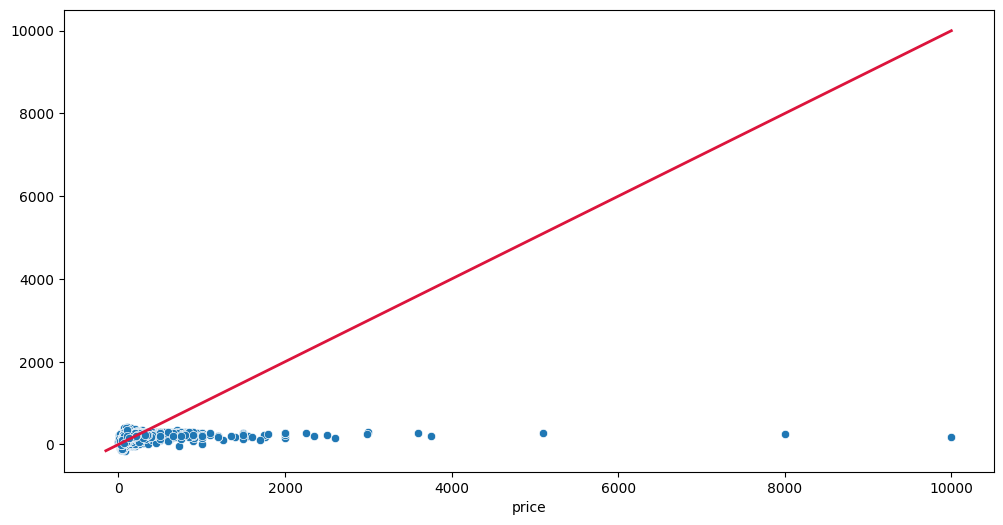

In [367]:
#plotting scatter plot
plt.figure(figsize=(12,6))
sns.scatterplot(x=y_test, y=y_test_pred)
#plotting line
min_val = min(y_test.min(), y_test_pred.min()) #making limit for the line
max_val = max(y_test.max(), y_test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='crimson', linewidth=2)

Task 7.2: Plot a Residual Plot (Errors vs. Predicted values) or an error
distribution histogram.

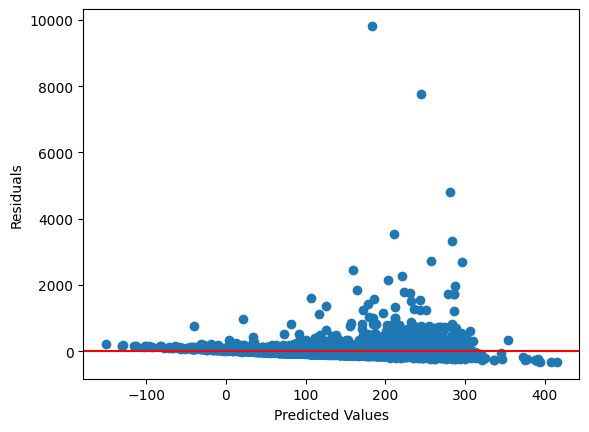

In [368]:
residual = y_test - y_test_pred
plt.scatter(y_test_pred, residual)
plt.axhline(y=0, color='red')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.show()

Task 7.3: Answer the final project question: Does the model perform
better on cheap listings or expensive listings, and why?

Model performs better on cheap listings as the prices increase they begin to move away from the median line/reference line, meaning they are farther away from the actual price.